# Is the region map distorted by the disease? Re-drawing it from disease-free genes

All three responder sections have almost no pallidum (0-0.7 % of cells vs 3-7 % elsewhere) and more "fibre tracts"
(analysis/11 A). The region labels (`RBD_compartment_simplified`) come from clustering neighbourhood-pooled
transcriptomes with **all** genes, so stressed OLs, microglia and astrocytes could pull a region into another cluster.
Every region-level result (findings 4, 5, 9, 14, the region DE of analysis/01) rests on these labels.

Approach (`utils/region_transfer.py`):

1. **Anatomy genes**: the 400 genes that differ most between regions in control pseudobulks, excluding every response
   gene (all prespecified programme sets, microglial markers, the OL driver genes and the region-consistent own
   changes of analysis/12). Genes that only *look* changed because a region is missing are deliberately kept.
2. **Same pooling as the original pipeline**: each cell's anatomy-gene counts summed with its 20 nearest neighbours.
3. **Label transfer from controls**: PCA + logistic regression trained on control cells with their original labels
   (controls are not diseased, so their map is the reference), checked by leaving one control section out, then
   applied to every section.
4. Re-run the key regional results on the new labels.

Input: `results/region_map/anatomy_counts.npz` (+ `.obs.csv.gz`, `.genes.txt`; `scripts/export_cell_counts.py
--genes-file`, office Mac; gitignored, 83 MB).

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import sparse
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import region_transfer as rt, composition as co, mosaic as mo
from utils.gene_sets import GENE_SETS, MECHANISM_SETS

OUT = REPO / "results" / "region_map"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]; age = sections["age"]
ctrl = sections.index[grp == "control"]; resp = sections.index[grp == "responder"]; nonr = sections.index[grp == "non-responder"]
order = list(ctrl) + list(nonr) + list(resp)

INK2, AXIS = "#52514e", "#c3c2b7"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b8b7b0"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]
STYLE = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE), "responder": dict(color=ORANGE)}
def save(fig, name, dpi=200):
    fig.savefig(FIG / f"{name}.png", dpi=dpi, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
def dots(ax, values, title, ylab=None, ref=None):
    for gi, g in enumerate(GROUP_ORDER):
        v = values[values.index.map(grp) == g].to_numpy()
        ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    if ref is not None: ax.axhline(ref, color=AXIS, lw=0.8)
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5); ax.set_title(title, fontsize=9)
    if ylab: ax.set_ylabel(ylab)
def ptxt(v):
    _, pr = co.exact_perm(v, resp, ctrl); _, pn = co.exact_perm(v, nonr, ctrl)
    return f"resp p={pr:.3f}, non-resp p={pn:.2f}"

## 1. Anatomy genes

In [2]:
RT = REPO / "results" / "region_time"
meta = pd.read_csv(RT / "pseudobulk_meta.csv", index_col=0)
counts = pd.read_csv(RT / "pseudobulk_counts.csv", index_col=0)
own = pd.read_csv(REPO / "results" / "celltype_de" / "tables" / "own_changes_with_region_lfc.csv")
drivers = pd.read_csv(REPO / "results" / "ol_gene_drivers" / "tables" / "driver_genes.csv", index_col=0).index
mg_markers = pd.read_csv(REPO / "results" / "celltype_de" / "tables" / "source_markers.csv", index_col=0).loc["Microglia", "markers"].split(", ")
exclude = (set(own[own.consistent == 1].gene) | set(drivers) | set(mg_markers)
           | {g for v in list(GENE_SETS.values()) + list(MECHANISM_SETS.values()) for g in v})
m = meta[(meta.region != "All regions") & meta.sample_id.isin(ctrl)]
Xr = counts.loc[m.index].groupby([m.region, m.sample_id]).sum()
L = np.log2(Xr.div(Xr.sum(1), axis=0) * 1e6 + 1)
F = rt.select_anatomy_genes(L, pd.Series(L.index.get_level_values(0)), exclude=exclude, n=400)
exported = [g.strip() for g in open(OUT / "anatomy_counts.npz.genes.txt") if g.strip()]
assert list(F.index) == exported, "exported gene list differs from the selection; re-export"
save_table(F.rename("F").round(3).to_frame(), "anatomy_genes")
(TAB / "anatomy_genes.txt").write_text("\n".join(F.index) + "\n")   # input for scripts/export_cell_counts.py --genes-file
print(f"{len(exclude)} response genes excluded; top anatomy genes:", ", ".join(F.index[:30]))

469 response genes excluded; top anatomy genes: Igf2, Bmp6, Slc16a8, Ogn, Chrm1, Rbp1, Pon3, Stx1a, Serping1, Prkcg, Steap1, Slc13a4, Rprml, Msx1, Gabra1, Egr3, Cd55, Camk2a, Tgfbr3, Camk2b, Ptk2b, Slc17a7, Htr2c, Cdh3, Gabrd, Agt, Cdh1, Slc22a6, Grin2a, Prelp


## 2-3. Neighbourhood pooling and label transfer from controls

In [3]:
X = sparse.load_npz(OUT / "anatomy_counts.npz").tocsr()
obs = pd.read_csv(OUT / "anatomy_counts.npz.obs.csv.gz")
xy = pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz", usecols=["cell_id", "sample_id", "x_centroid", "y_centroid"])
obs = obs.merge(xy, on=["cell_id", "sample_id"], how="left"); assert obs.x_centroid.notna().all()
N = rt.log_normalise(rt.neighbour_pool(X, obs.sample_id.to_numpy(), obs[["x_centroid", "y_centroid"]].to_numpy(), k=20))
labels = obs.region.to_numpy(); sample = obs.sample_id.to_numpy()
ref = obs.sample_id.isin(ctrl).to_numpy() & (labels != "Unknown")
model = rt.RegionTransfer(n_pcs=30)
Z = model.embed_fit(N, ref)
acc = save_table(model.loco_accuracy(Z, labels, sample, list(ctrl), ref).round(4).to_frame(), "held_out_accuracy")
display(acc.T)
model.fit(Z, labels, ref)
obs["region_new"], obs["p_new"] = model.predict(Z)
obs[["cell_id", "sample_id", "region", "region_new", "p_new"]].round(4).to_csv(OUT / "region_transfer_labels.csv.gz", index=False)

,RB4620,RB4658,RB4676,RB4282,RB4350,RB4498
held_out_accuracy,0.9364,0.9036,0.9459,0.9424,0.9431,0.9404


**2-3.** Held out, the disease-free model reproduces a control section's original labels for 90-95 % of cells
(the rest are mostly region borders), so the anatomy genes carry the region map on their own.

## 4. What changes in the mtDSB sections?

,responders,controls
region_new,,
Fiber tracts,0.658,0.910
Pallidum,0.229,0.042
Hypothalamus,0.044,0.001
Meningeal border/glia limitans,0.015,0.009
Thalamus,0.015,0.006
Cortex,0.013,0.013


,controls,non-responders,responders
region,,,
Cortex,0.024,0.029,0.024
Thalamus,0.023,0.039,0.012
Striatum,0.041,0.033,0.060
Hypothalamus,0.043,0.114,0.060
Fiber tracts,0.090,0.095,0.331
Pallidum,0.248,0.345,0.423
Hippocampus,0.038,0.020,0.028
Olfactory areas,0.101,0.228,0.098
Ventricular system,0.036,0.033,0.022


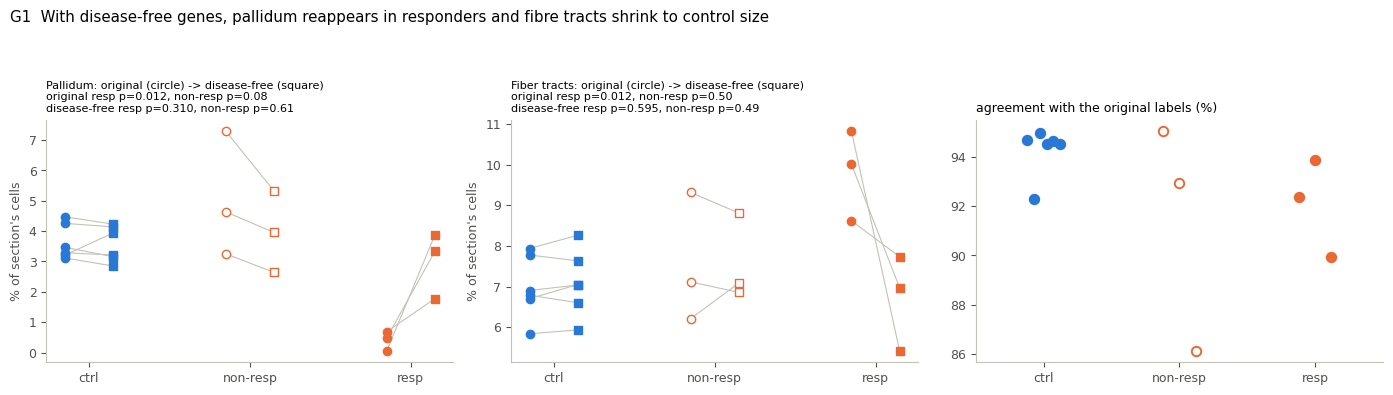

In [4]:
REG = ["Cortex", "Thalamus", "Striatum", "Hypothalamus", "Fiber tracts", "Pallidum", "Hippocampus", "Olfactory areas",
       "Ventricular system", "Meningeal border/glia limitans", "Vasculature", "Unknown"]
share = lambda col: (obs.groupby(["sample_id", col]).size().unstack().reindex(columns=REG).fillna(0)
                     .pipe(lambda t: 100 * t.div(t.sum(1), axis=0)).loc[order])
old, new = share("region"), share("region_new")
k = obs.region != "Unknown"
agree = (obs[k].region == obs[k].region_new).groupby(obs[k].sample_id).mean().loc[order]
cov = save_table(pd.concat({"original": old, "disease_free": new}, axis=1).round(2), "region_coverage_both_maps")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 1, 1]})
for ax, r in zip(axes[:2], ["Pallidum", "Fiber tracts"]):
    for gi, g in enumerate(GROUP_ORDER):
        ss = [s for s in order if grp[s] == g]
        for s in ss:
            ax.plot([gi - 0.15, gi + 0.15], [old.loc[s, r], new.loc[s, r]], color=AXIS, lw=0.8, zorder=1)
        ax.scatter(np.full(len(ss), gi - 0.15), old.loc[ss, r], s=36, zorder=3, **STYLE[g])
        ax.scatter(np.full(len(ss), gi + 0.15), new.loc[ss, r], s=36, zorder=3, marker="s", **STYLE[g])
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_ylabel("% of section's cells")
    ax.set_title(f"{r}: original (circle) -> disease-free (square)\noriginal {ptxt(old[r])}\ndisease-free {ptxt(new[r])}", fontsize=8)
dots(axes[2], 100 * agree, "agreement with the original labels (%)")
fig.suptitle("G1  With disease-free genes, pallidum reappears in responders and fibre tracts shrink to control size", x=0.01, ha="left", y=1.08)
fig.tight_layout(); save(fig, "G1_coverage_both_maps")

# where did the responder "fibre tracts" go?
rs = obs[obs.sample_id.isin(resp) & (obs.region == "Fiber tracts")]
cs = obs[obs.sample_id.isin(ctrl) & (obs.region == "Fiber tracts")]
moved = pd.DataFrame({"responders": rs.region_new.value_counts(normalize=True), "controls": cs.region_new.value_counts(normalize=True)}).fillna(0).round(3)
save_table(moved, "original_fibre_tracts_relabelled")
display(moved.sort_values("responders", ascending=False).head(6))
# share of each original region's cells that get another label (bias bound for region-level DE)
rel = (obs[k].assign(changed=obs[k].region != obs[k].region_new).groupby(["sample_id", "region"]).changed.mean().unstack().loc[order])
relg = save_table(pd.DataFrame({"controls": rel.loc[ctrl].mean(), "non-responders": rel.loc[nonr].mean(), "responders": rel.loc[resp].mean()}).round(3), "relabelled_share_by_region")
display(relg.loc[[r for r in REG if r in relg.index]])

**4.** The disease-free map puts pallidum back into the responder sections (RB4405 0.04 -> 3.9 %, RB4627 0.5 -> 3.3 %,
RB4401 0.7 -> 1.8 %; controls 2.9-4.2 %) and shrinks their fibre tracts to the control range. Of the cells originally
called "fibre tracts" in responders, 23 % are pallidum by anatomy genes and 66 % stay fibre tracts (controls: 4 % and
91 %).
So **the original map was distorted by the disease**: the white-matter-rich pallidum, full of stressed OLs and
microglia in responders, clustered with the fibre tracts. Section plane is not the explanation (RB4401 keeps somewhat
less pallidum, which may be plane). Outside pallidum and fibre tracts the two maps agree as well in responders as in
controls (2-6 % of cells relabelled per region, borders and vasculature more); the over-segmented non-responder RB4403
differs more in hypothalamus and olfactory areas.

## 5. Re-running the regional results on the disease-free map

map                                              disease_free  original
metric                          region                                 
OL share above control 90th pct Cortex                  0.012     0.012
                                Fiber tracts            0.012     0.012
                                Hippocampus             0.036     0.024
                                Hypothalamus            0.012     0.012
                                Olfactory areas         0.071     0.071
                                Pallidum                0.012     0.012
                                Striatum                0.012     0.012
                                Thalamus                0.012     0.012
microglia per mm2               Cortex                  0.357     0.298
                                Fiber tracts            0.036     0.012
                                Hippocampus             0.667     0.905
                                Hypothalamus            0.036     0.060
                                Olfactory areas         0.560     0.369
                                Pallidum                0.095     0.024
                                Striatum                0.798     0.595
                                Thalamus                0.012     0.012

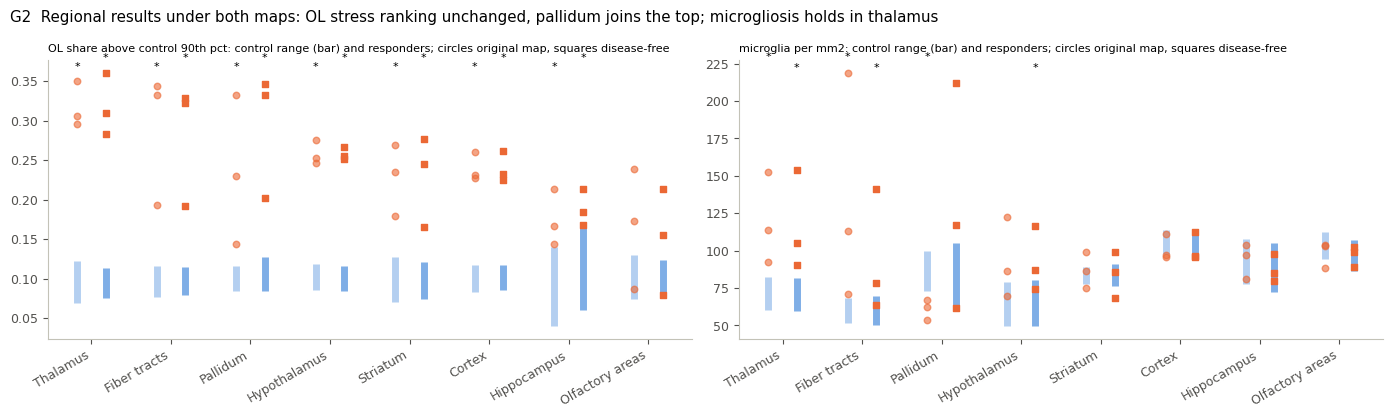

In [5]:
ol = pd.read_csv(REPO / "results" / "cell_table" / "ol_gene_scores.csv.gz").merge(obs[["cell_id", "sample_id", "region_new"]], on=["cell_id", "sample_id"])
cells = (pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz").rename(columns={"RBD_compartment_simplified": "region"})
         .merge(obs[["cell_id", "sample_id", "region_new"]], on=["cell_id", "sample_id"]))
cells["cell_type"] = cells.cell_class.replace({"DA-Oligodendrocytes": "Oligodendrocytes"})
MAIN = ["Thalamus", "Fiber tracts", "Pallidum", "Hypothalamus", "Striatum", "Cortex", "Hippocampus", "Olfactory areas"]
rows = []
for mapname, col in (("original", "region"), ("disease_free", "region_new")):
    o = ol[ol[col] != "Unknown"].drop(columns=["region"]).rename(columns={col: "region"}) if col == "region_new" else ol[ol.region != "Unknown"].copy()
    o["u"] = mo.loo_percentiles(o, "isr", grp, age)
    tail = o.groupby(["sample_id", "region"]).u.apply(lambda v: (v > 0.9).mean()).unstack()
    d = co.region_density(cells.assign(region=cells[col]))
    for r in MAIN:
        t = tail[r].reindex(order).fillna(0)
        mg = d[(d.cell_type == "Microglia") & (d.region == r)].set_index("sample_id").density.reindex(order).fillna(0)
        for metric, v in (("OL share above control 90th pct", t), ("microglia per mm2", mg)):
            _, p = co.exact_perm(v, resp, ctrl)
            rows.append({"map": mapname, "region": r, "metric": metric, "ctrl_min": v[ctrl].min(), "ctrl_max": v[ctrl].max(),
                         **{s: v[s] for s in resp}, "nonresp_mean": v[nonr].mean(), "p_resp": p})
rr = save_table(pd.DataFrame(rows).round(3), "regional_results_both_maps", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, metric in zip(axes, ["OL share above control 90th pct", "microglia per mm2"]):
    for j, (mapname, dx, mk) in enumerate((("original", -0.18, "o"), ("disease_free", 0.18, "s"))):
        t = rr[(rr.metric == metric) & (rr["map"] == mapname)].set_index("region").loc[MAIN]
        x = np.arange(len(MAIN)) + dx
        ax.vlines(x, t.ctrl_min, t.ctrl_max, color=BLUE, lw=5, alpha=0.35 if j == 0 else 0.6)
        for s in resp:
            ax.scatter(x, t[s], color=ORANGE, marker=mk, s=22, zorder=3, alpha=0.6 if j == 0 else 1)
        for xi, p in zip(x, t.p_resp):
            if p < 0.05: ax.text(xi, ax.get_ylim()[1] if False else t[list(resp)].max().max() * 1.04, "*", ha="center", fontsize=8)
    ax.set_xticks(range(len(MAIN)), MAIN, rotation=30, ha="right")
    ax.set_title(f"{metric}: control range (bar) and responders; circles original map, squares disease-free", fontsize=8)
fig.suptitle("G2  Regional results under both maps: OL stress ranking unchanged, pallidum joins the top; microgliosis holds in thalamus", x=0.01, ha="left")
fig.tight_layout(); save(fig, "G2_regional_results_both_maps")
display(rr.pivot_table(index=["metric", "region"], columns="map", values="p_resp").round(3))

**5.**

* **OL stress by region (finding 4) holds.** With the disease-free map, thalamus (28-36 % of OLs above the control 90th
  percentile vs 8-11 %) and fibre tracts (19-33 %) remain at the top, and **pallidum joins them** (20-35 % vs 9-13 %;
  under the old map it held only a few hundred responder OLs). Cortex, striatum and hypothalamus stay mid-ranked
  (17-28 %), hippocampus and olfactory areas lowest. All regions are affected in responders, as before.
* **Microgliosis (finding 14)**: thalamus is unchanged (90-154 vs 60-82 /mm2, p = 0.012) and hypothalamus becomes
  significant (p = 0.036). Fibre tracts weaken (63-141 vs 51-70, p = 0.036, RB4401 inside the control range): part
  of the old fibre-tract excess was pallidum, where RB4405 and RB4627 now have 212 and 117 microglia /mm2 against
  62-105 in controls. The label-free analysis (analysis/11 C) is unaffected by any of this.

## 6. Maps

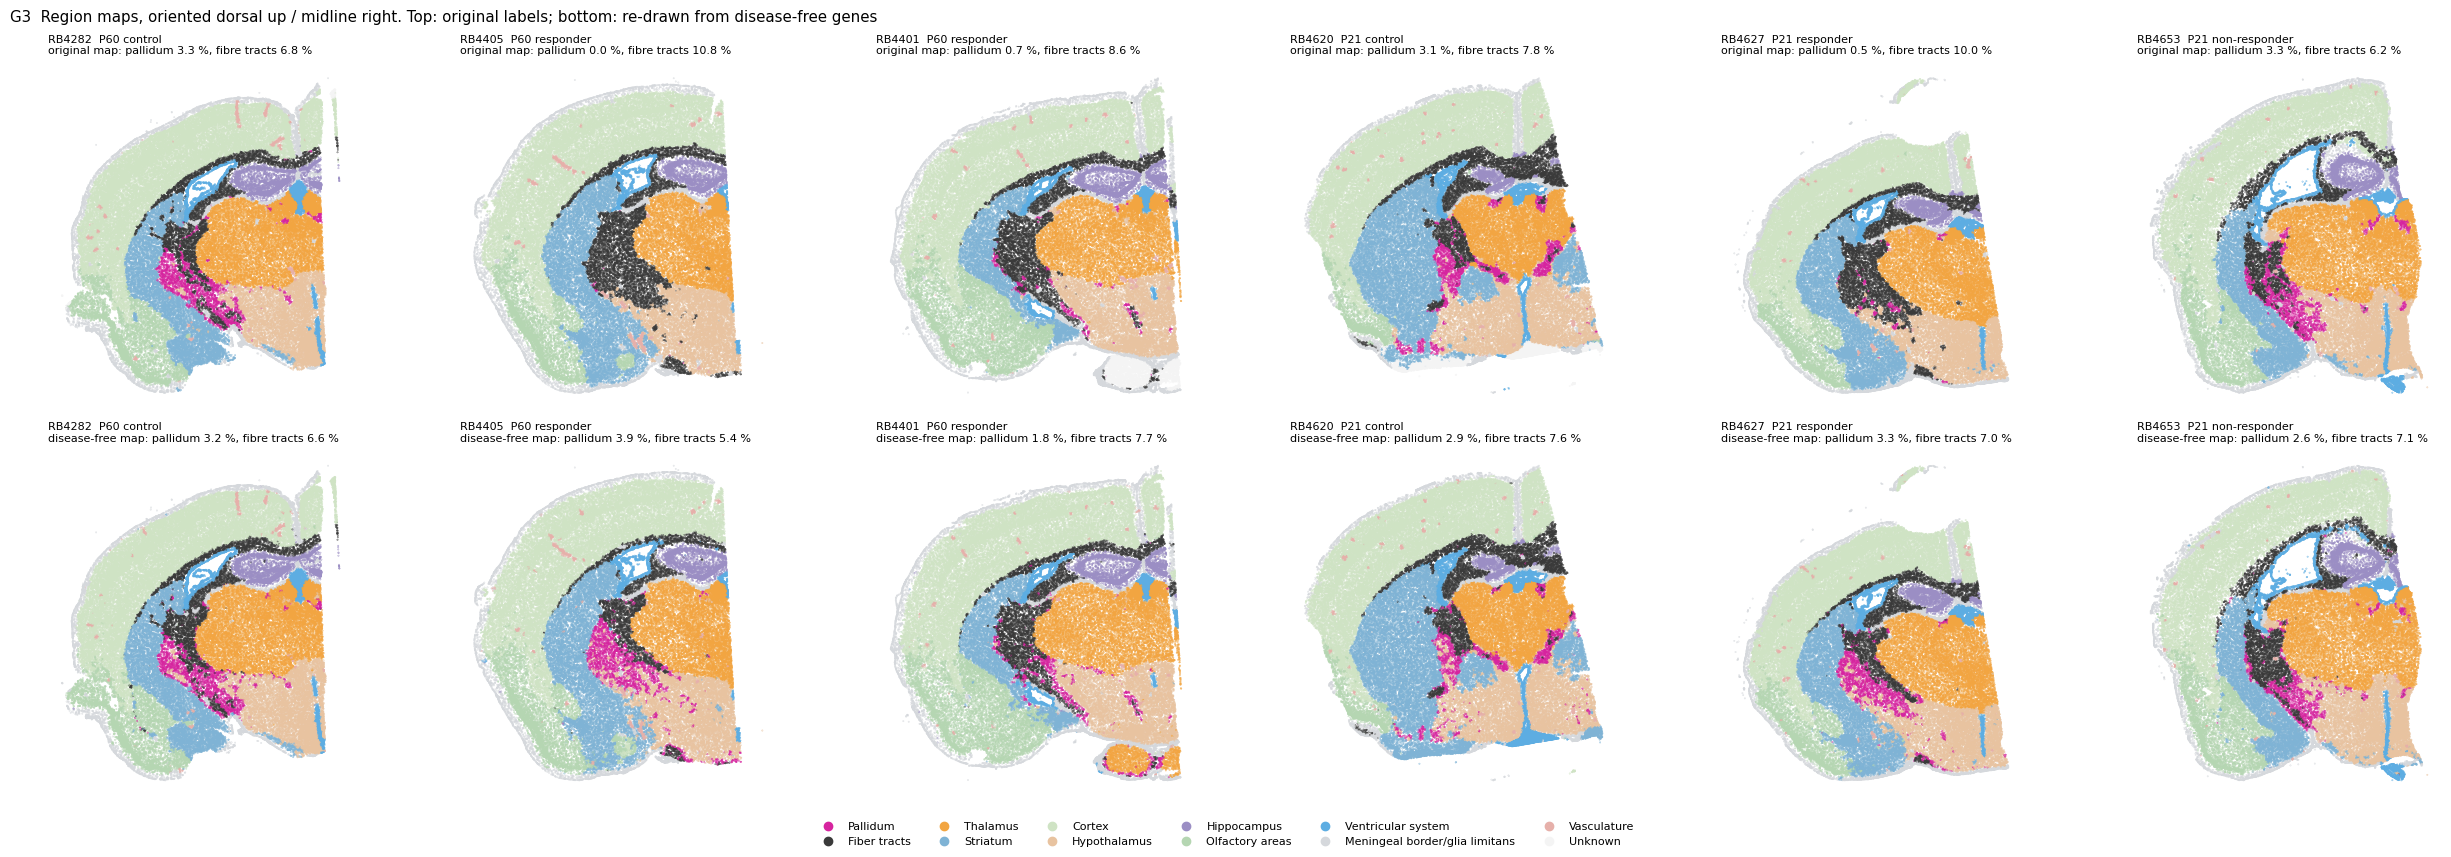

In [6]:
from utils.spatial_orientation import apply_orientation
orient = pd.read_csv(REPO / "results" / "cell_table" / "section_orientation.csv", index_col=0)
mp = apply_orientation(obs, orient)
COL = {"Pallidum": "#d6249f", "Fiber tracts": "#3a3a3a", "Thalamus": "#f2a541", "Striatum": "#7fb3d5", "Cortex": "#cfe3c4",
       "Hypothalamus": "#e8c3a0", "Hippocampus": "#9b8ec4", "Olfactory areas": "#b5d6b2", "Ventricular system": "#5dade2",
       "Meningeal border/glia limitans": "#d5d8dc", "Vasculature": "#e6b0aa", "Unknown": "#f4f4f4"}
SHOW = [("RB4282", "P60 control"), ("RB4405", "P60 responder"), ("RB4401", "P60 responder"),
        ("RB4620", "P21 control"), ("RB4627", "P21 responder"), ("RB4653", "P21 non-responder")]
fig, axes = plt.subplots(2, len(SHOW), figsize=(4.2 * len(SHOW), 8.6))
for j, (sid, lab) in enumerate(SHOW):
    sec = mp[mp.sample_id == sid]
    for i, (col, name) in enumerate((("region", "original map"), ("region_new", "disease-free map"))):
        ax = axes[i, j]
        ax.scatter(sec.x_oriented, sec.y_oriented, s=0.08, c=sec[col].map(COL).fillna("#f4f4f4"), rasterized=True)
        pal = 100 * (sec[col] == "Pallidum").mean(); fib = 100 * (sec[col] == "Fiber tracts").mean()
        ax.set_title(f"{sid}  {lab}\n{name}: pallidum {pal:.1f} %, fibre tracts {fib:.1f} %", fontsize=8)
        ax.set_aspect("equal"); ax.axis("off")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=r) for r, c in COL.items()]
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, fontsize=8)
fig.suptitle("G3  Region maps, oriented dorsal up / midline right. Top: original labels; bottom: re-drawn from disease-free genes", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.05, 1, 1)); save(fig, "G3_maps_both", dpi=150)

**6.** In the controls and the non-responder the two maps look alike. In the responders the original map paints the
pallidum (magenta, beside the internal capsule) as fibre tract (dark grey); the disease-free map restores it in
roughly the place and size seen in controls.

## Summary

* **The transcript-based region map was distorted by the disease**, not by section plane: in responders most of the
  pallidum was called "fibre tracts" (23 % of their "fibre tract" cells are pallidum). A map from 400 disease-free anatomy genes, trained on controls (90-95 % held-out
  agreement), restores pallidum to control levels.
* **The main regional conclusions survive**: OL stress is brain-wide and highest in thalamus, fibre tracts and now
  pallidum (the white-matter-rich basal ganglia output); microgliosis is strongest in thalamus, pallidum and
  hypothalamus. Fibre-tract-specific statements should be phrased as "white matter including the pallidum".
* **For future region-level analyses** use `region_transfer_labels.csv.gz` (`region_new`), or at least treat pallidum
  and fibre tracts together. The region DE of analysis/01 used the original labels; in responders about a quarter of
  its "fibre tract" cells are pallidum (and pallidum is nearly empty), which mainly blurs those two regions.